In [6]:
#data seperation
residential=[
    "Apartment", "Villa", "Townhouse", "Duplex",
               "Twin House", "Penthouse", "Chalet", "iVilla",
               "Hotel Apartment"
]
df = df[(df["price_period"] == "sell") &
        (df["property_type"].isin(residential))]
#drop cols with same value
df.drop(
    columns=['currency','record_type','price_period']
)
df.shape

(19701, 25)

In [2]:
import pandas as pd
import numpy as np
df=pd.read_csv("all_egypt.csv")
df.shape
print("Info: ",df.info())
df = pd.read_csv("all_egypt.csv", low_memory=False)
print("Null: ",df.isnull().sum())
df.head(5)
df.describe()



C:\Users\l\AppData\Local\Temp\ipykernel_22100\276899267.py:3: DtypeWarning: Columns (0: id) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("all_egypt.csv")


<class 'pandas.DataFrame'>
RangeIndex: 64106 entries, 0 to 64105
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               64106 non-null  object 
 1   title            64106 non-null  str    
 2   price            62977 non-null  float64
 3   currency         62985 non-null  str    
 4   price_period     62985 non-null  str    
 5   price_type       62985 non-null  str    
 6   price_raw_value  62985 non-null  float64
 7   property_type    62985 non-null  str    
 8   location         62985 non-null  str    
 9   latitude         64106 non-null  float64
 10  longitude        64106 non-null  float64
 11  images           64106 non-null  str    
 12  share_url        62985 non-null  str    
 13  bedrooms         52593 non-null  float64
 14  bathrooms        60228 non-null  float64
 15  size             62985 non-null  float64
 16  amenities        62985 non-null  str    
 17  category         64106 

,price,price_raw_value,latitude,longitude,bedrooms,bathrooms,size,page,min_price,max_price
count,6.297700e+04,6.298500e+04,64106.000000,64106.000000,52593.000000,60228.000000,6.298500e+04,64106.000000,0.0,0.0
mean,1.013712e+07,1.013585e+07,29.936054,31.291449,3.010686,2.599638,4.621353e+02,337.002933,NaN,NaN
std,4.106258e+07,4.106012e+07,1.483013,1.167402,1.343315,1.388999,1.460059e+04,221.131582,NaN,NaN
min,1.000000e+03,1.000000e+03,0.000000,0.000000,1.000000,1.000000,1.000000e+00,1.000000,NaN,NaN
25%,7.000000e+04,7.000000e+04,29.999271,31.028166,2.000000,2.000000,1.060000e+02,150.000000,NaN,NaN
50%,4.850000e+05,4.840000e+05,30.024694,31.449591,3.000000,2.000000,1.670000e+02,310.000000,NaN,NaN
75%,9.050000e+06,9.048530e+06,30.061470,31.538992,4.000000,3.000000,2.570000e+02,508.000000,NaN,NaN
max,1.000000e+09,1.000000e+09,31.571518,34.632736,7.000000,7.000000,2.520000e+06,800.000000,NaN,NaN


In [9]:
import pandas as pd

#delete unneccssary raws
print("Before: ",df.shape)
df = df.drop(columns=["min_price", "max_price", "images", "share_url",
                     "scraped_at_utc", "page"])


print("After: ",df.shape)
#delete raws without prices and locations
df.dropna(subset=['price','location'], inplace=True)
print(df.shape)

Before:  (19701, 25)
After:  (19701, 19)
(19701, 19)


C:\Users\l\AppData\Local\Temp\ipykernel_22100\2588689600.py:11: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['price','location'], inplace=True)


In [10]:
#know more info about data
print(df["price_period"].value_counts())
print(df["currency"].value_counts())
print(df["property_type"].value_counts())
print(df["record_type"].value_counts())

price_period
sell    19701
Name: count, dtype: int64
currency
EGP    19701
Name: count, dtype: int64
property_type
Apartment          10254
Villa               3353
Chalet              2068
Townhouse           1472
Twin House           904
Duplex               628
Penthouse            583
iVilla               289
Hotel Apartment      150
Name: count, dtype: int64
record_type
property    19701
Name: count, dtype: int64


In [11]:
#show prices and sizes problems
print(df[["price", "size", "bedrooms", "bathrooms"]].describe())
print(df["bedrooms"].isnull().sum())

              price          size      bedrooms     bathrooms
count  1.970100e+04  19701.000000  19156.000000  19700.000000
mean   1.538533e+07    199.717933      3.068281      2.945431
std    2.037671e+07    350.867293      1.104574      1.278919
min    2.000000e+05      2.000000      1.000000      1.000000
25%    5.670000e+06    115.000000      2.000000      2.000000
50%    1.000000e+07    165.000000      3.000000      3.000000
75%    1.800000e+07    235.000000      4.000000      4.000000
max    6.028291e+08  32000.000000      7.000000      7.000000
545


In [12]:
#know prices per meter and know how many sizes is not normal
df['price_per_sqm']=df['price']/df['size']
print(df["price_per_sqm"].describe())
print(df[df["size"] < 30].shape)
print(df[df["size"] > 1000].shape)

count     19701.000000
mean      80432.348031
std       51720.934151
min        1364.190024
25%       45630.901288
50%       68383.333333
75%      100000.000000
max      356452.850000
Name: price_per_sqm, dtype: float64
(1198, 19)
(116, 19)


In [13]:
#Types of small sizes
small = df[df["size"] < 30]
print(small["property_type"].value_counts())
print(small[["property_type", "price", "size", "location"]].head(10))
print(small["size"].value_counts().head(10))

property_type
Apartment          721
Villa              274
Chalet             149
Penthouse           22
Twin House          13
Duplex              11
iVilla               6
Hotel Apartment      2
Name: count, dtype: int64
      property_type      price  size  \
19986     Apartment  1100000.0  20.0   
20013         Villa  5000000.0  20.0   
20015        Chalet   910000.0  20.0   
20016     Apartment   800000.0  20.0   
20019     Apartment  1150000.0  25.0   
20085         Villa  2400000.0  20.0   
20098         Villa  4900000.0  20.0   
20103     Apartment  5500000.0  20.0   
20132        Chalet  3300000.0  20.0   
20133         Villa  4300000.0  20.0   

                                                location  
19986  U One, Sheikh Zayed Compounds, Sheikh Zayed Ci...  
20013         Mesca, Soma Bay, Safaga, Hurghada, Red Sea  
20015       La Vista 6, La Vista, Al Ain Al Sokhna, Suez  
20016  IL Bosco, New Capital Compounds, New Capital C...  
20019          Stoda, Sheraton Al Matar,

In [14]:
#delete size less than 30M
df = df[df["size"] >= 30]
print(df.shape)

(18503, 19)


In [15]:
#know info about big sizes
big = df[df["size"] > 1000]
print(big["property_type"].value_counts())
print(big[["property_type", "price", "size", "location"]].head(10))
print(big["size"].value_counts().head(10))

property_type
Villa              109
Hotel Apartment      6
Apartment            1
Name: count, dtype: int64
      property_type        price    size  \
19987         Villa   68000000.0  1150.0   
20531         Villa   45000000.0  1050.0   
20791         Villa  125000000.0  1200.0   
20883         Villa  142000000.0  1100.0   
21895         Villa  188000000.0  1050.0   
22785         Villa   35000000.0  1030.0   
22888         Villa  134000000.0  1500.0   
22889         Villa  145000000.0  1300.0   
22912         Villa  190000000.0  1550.0   
23098         Villa  125000000.0  1300.0   

                                                location  
19987  Al  Rabwa, Sheikh Zayed Compounds, Sheikh Zaye...  
20531  Mena Garden City, Al Motamayez District, 6 Oct...  
20791  Katameya Dunes, El Katameya Compounds, El Kata...  
20883  Swan Lake Katameya, The 1st Settlement, New Ca...  
21895  Katameya Dunes, El Katameya Compounds, El Kata...  
22785        Alex West, Alexandria Compounds, Alexan

In [16]:
#highest and lowest 1%
print(df["price_per_sqm"].quantile([0.01, 0.05, 0.95, 0.99]))
print(df.nlargest(5, "price_per_sqm")[["property_type", "price", "size", "location"]])
print(df.nsmallest(5, "price_per_sqm")[["property_type", "price", "size", "location"]])

0.01     14501.176471
0.05     24666.445220
0.95    155129.689580
0.99    223200.000000
Name: price_per_sqm, dtype: float64
      property_type        price   size  \
34228    Twin House   21230000.0   60.0   
37841         Villa  182000000.0  515.0   
34141         Villa   70500000.0  200.0   
34143         Villa   70500000.0  200.0   
24261     Townhouse   21000000.0   60.0   

                                                location  
34228         Mesca, Soma Bay, Safaga, Hurghada, Red Sea  
37841  Swan Lake West, 6 October Compounds, 6 October...  
34141                Sabina, El Gouna, Hurghada, Red Sea  
34143   Mangroovy Residence, El Gouna, Hurghada, Red Sea  
24261      Soul North Coast, Qesm Ad Dabaah, North Coast  
      property_type      price   size  \
20596         Villa   574324.0  421.0   
20809         Villa  1100000.0  500.0   
20865         Villa  1500000.0  583.0   
21200     Apartment   414000.0  155.0   
26003     Apartment   500000.0  175.0   

                

In [17]:
#check for 0.99 quantile
threshold = df["price_per_sqm"].quantile(0.99)
high_price = df[df["price_per_sqm"] > threshold]
print("Threshold:", threshold)
print("Rows to remove:", len(high_price))
print("Percentage:", len(high_price) / len(df) * 100)

Threshold: 223200.0
Rows to remove: 185
Percentage: 0.999837864130141


In [18]:
low = df["price_per_sqm"].quantile(0.01)
high = df["price_per_sqm"].quantile(0.99)
df = df[df["price_per_sqm"].between(low, high)]

df["area_name"] = df["location"].str.split(",").str[0].str.strip()

df.to_csv("cleaned_egypt_real_estate.csv", index=False)

print(df.shape)
print(df["area_name"].value_counts().head(10))

(18132, 19)
area_name
Hyde Park               476
Palm Hills New Cairo    386
Mountain View iCity     367
IL Monte Galala         326
Privado                 269
Mivida                  267
O West                  258
El Patio Oro            246
Al Ahyaa District       241
Villette                241
Name: count, dtype: int64


In [48]:
df.isnull().sum().sort_values(ascending=False)


bedrooms                    542
bathrooms                     1
id                            0
title                         0
currency                      0
price                         0
price_raw_value               0
price_period                  0
property_type                 0
location                      0
latitude                      0
price_type                    0
longitude                     0
size                          0
amenities                     0
category                      0
record_type                   0
price_per_sqm                 0
calculated_price_per_sqm      0
price_difference              0
dtype: int64

In [21]:
#bedrooms
print(df["bedrooms"].describe())
print(df["bedrooms"].value_counts().sort_index())
print(df.groupby("property_type")["bedrooms"].median())

df["bedrooms"] = df["bedrooms"].fillna(
    df.groupby("property_type")["bedrooms"]
    .transform("median")
)
print(df["bedrooms"].isnull().sum())

count    17595.000000
mean         3.053083
std          1.112324
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          7.000000
Name: bedrooms, dtype: float64
bedrooms
1.0    1152
2.0    3647
3.0    8238
4.0    3014
5.0     990
6.0     325
7.0     229
Name: count, dtype: int64
property_type
Apartment          3.0
Chalet             2.0
Duplex             3.0
Hotel Apartment    1.0
Penthouse          3.0
Townhouse          3.0
Twin House         4.0
Villa              4.0
iVilla             3.0
Name: bedrooms, dtype: float64
0


In [22]:
#bathrooms
print(df["bathrooms"].describe())
print(df["bathrooms"].value_counts().sort_index())

df["bathrooms"] = df["bathrooms"].fillna(
    df["bathrooms"].median()
)
df['bathrooms'].isnull().sum()

count    18131.000000
mean         2.928741
std          1.288969
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          7.000000
Name: bathrooms, dtype: float64
bathrooms
1.0    2272
2.0    4651
3.0    6230
4.0    3087
5.0    1184
6.0     380
7.0     327
Name: count, dtype: int64


np.int64(0)

In [23]:
#check for data
print("Dataset Shape:", df.shape)

print("Duplicates:", df.duplicated().sum())

print("Missing Values:", df.isnull().sum())

print(df.dtypes)

Dataset Shape: (18132, 19)
Duplicates: 0
Missing Values: id                 0
title              0
price              0
currency           0
price_period       0
price_type         0
price_raw_value    0
property_type      0
location           0
latitude           0
longitude          0
bedrooms           0
bathrooms          0
size               0
amenities          0
category           0
record_type        0
price_per_sqm      0
area_name          0
dtype: int64
id                     str
title                  str
price              float64
currency               str
price_period           str
price_type             str
price_raw_value    float64
property_type          str
location               str
latitude           float64
longitude          float64
bedrooms           float64
bathrooms          float64
size               float64
amenities              str
category               str
record_type            str
price_per_sqm      float64
area_name           object
dtype: object


In [28]:

#df = df.drop(columns=["currency", "price_period", "record_type"])
print(df.columns.tolist())

['id', 'title', 'price', 'price_type', 'price_raw_value', 'property_type', 'location', 'latitude', 'longitude', 'bedrooms', 'bathrooms', 'size', 'amenities', 'category', 'price_per_sqm', 'area_name']


In [30]:
print(df["location"].str.split(",").str.len().value_counts())
print(df["location"].sample(5, random_state=1).tolist())
df["city"] = df["location"].str.split(",").str[-2].str.strip()
print(df["city"].value_counts().head(15))
print(df.shape)

location
4    8341
5    5768
3    3856
2     167
Name: count, dtype: int64
['Dyar Park, Ext North Inves Area, New Cairo City, Cairo', 'New Giza, Cairo Alexandria Desert Road, 6 October City, Giza', 'Vinci, New Capital Compounds, New Capital City, Cairo', 'South Lotus, El Lotus, New Cairo City, Cairo', 'Forty West, Sheikh Zayed Compounds, Sheikh Zayed City, Giza']
city
New Cairo City                  6554
6 October City                  2109
Sheikh Zayed City               2026
Hurghada                        1830
Mostakbal City - Future City     879
Al Ain Al Sokhna                 836
New Capital City                 500
Ras Al Hekma                     359
Sidi Abdel Rahman                354
Madinaty                         326
Shorouk City                     296
Qesm Marsa Matrouh               259
Al Alamein                       259
Qesm Ad Dabaah                   210
New Heliopolis                   191
Name: count, dtype: int64
(18132, 17)


In [31]:
print((df["latitude"] == 0).sum(), (df["longitude"] == 0).sum())
print(df[(df["property_type"] == "Villa") & (df["size"] < 100)].shape)
print(df.duplicated(subset=["title", "price", "size", "location"]).sum())
print((df["price"] == df["price_raw_value"]).mean())
print(df["price_type"].value_counts())
print(df["category"].value_counts())

0 0
(111, 17)
360
1.0
price_type
sale_price    18132
Name: count, dtype: int64
category
buy               18092
commercial_buy       40
Name: count, dtype: int64


In [32]:

df = df.drop_duplicates(subset=["title", "price", "size", "location"])


df = df[df["category"] == "buy"]

df = df.drop(columns=["price_raw_value", "price_type", "category"])

print(df.shape)

small_villas = df[(df["property_type"] == "Villa") & (df["size"] < 100)]
print(small_villas["size"].value_counts().head())

(17734, 14)
size
50.0    54
30.0     7
45.0     7
60.0     6
40.0     5
Name: count, dtype: int64


In [33]:
df = df[~((df["property_type"] == "Villa") & (df["size"] < 100))]
print(df.shape)

df.to_csv("cleaned_egypt_real_estate.csv", index=False)

(17626, 14)


city
North Coast                     106666.666667
Mokattam                        105376.344086
Hurghada                         85706.373913
Al Ain Al Sokhna                 70588.235294
New Cairo City                   67791.005291
Sheikh Zayed City                65986.111111
New Heliopolis                   64705.882353
6 October City                   63981.340476
Madinaty                         56521.739130
New Capital City                 52226.666667
Shorouk City                     45273.389706
Hay Sharq                        41208.791209
Mostakbal City - Future City     36538.461538
Hay El Maadi                     31481.481481
Name: price_per_sqm, dtype: float64


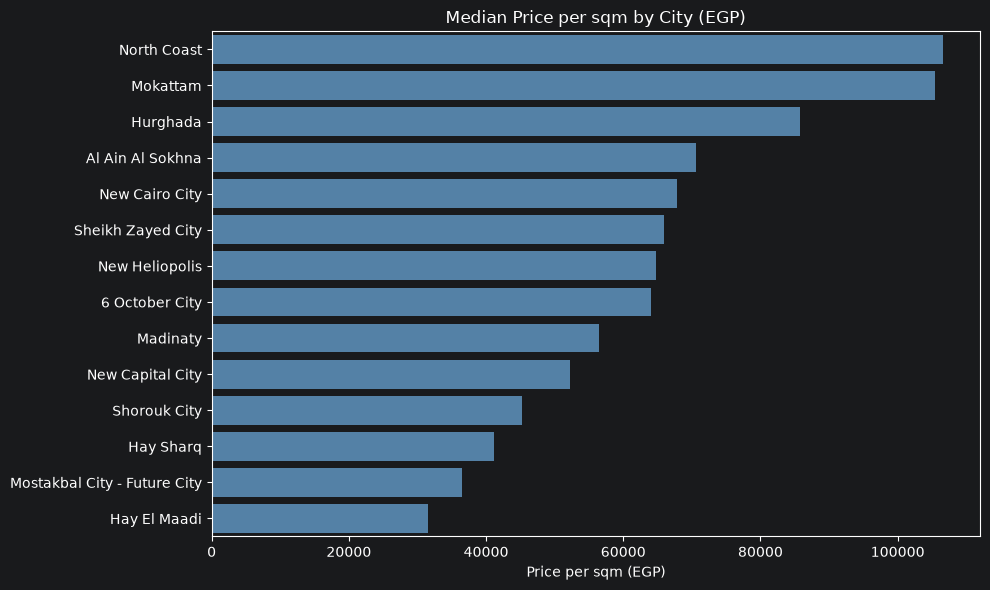

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns


north_coast = ["Ras Al Hekma", "Sidi Abdel Rahman", "Al Alamein",
               "Qesm Ad Dabaah", "Qesm Marsa Matrouh"]
df["city"] = df["city"].replace(north_coast, "North Coast")


counts = df["city"].value_counts()
data = df[df["city"].isin(counts[counts >= 100].index)]


result = (data.groupby("city")["price_per_sqm"]
              .median()
              .sort_values(ascending=False))
print(result)


plt.figure(figsize=(10, 6))
sns.barplot(x=result.values, y=result.index, color="steelblue")
plt.title("Median Price per sqm by City (EGP)")
plt.xlabel("Price per sqm (EGP)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("price_per_sqm_by_city.png", dpi=150)
plt.show()

In [35]:
for c in ["Mokattam", "Hay Sharq", "Hay El Maadi"]:
    print(c, len(df[df["city"] == c]))

Mokattam 119
Hay Sharq 163
Hay El Maadi 145


city
North Coast                     106666.666667
Hurghada                         85706.373913
Al Ain Al Sokhna                 70588.235294
New Cairo City                   67791.005291
Sheikh Zayed City                65986.111111
6 October City                   63981.340476
Madinaty                         56521.739130
New Capital City                 52226.666667
Shorouk City                     45273.389706
Mostakbal City - Future City     36538.461538
Name: price_per_sqm, dtype: float64


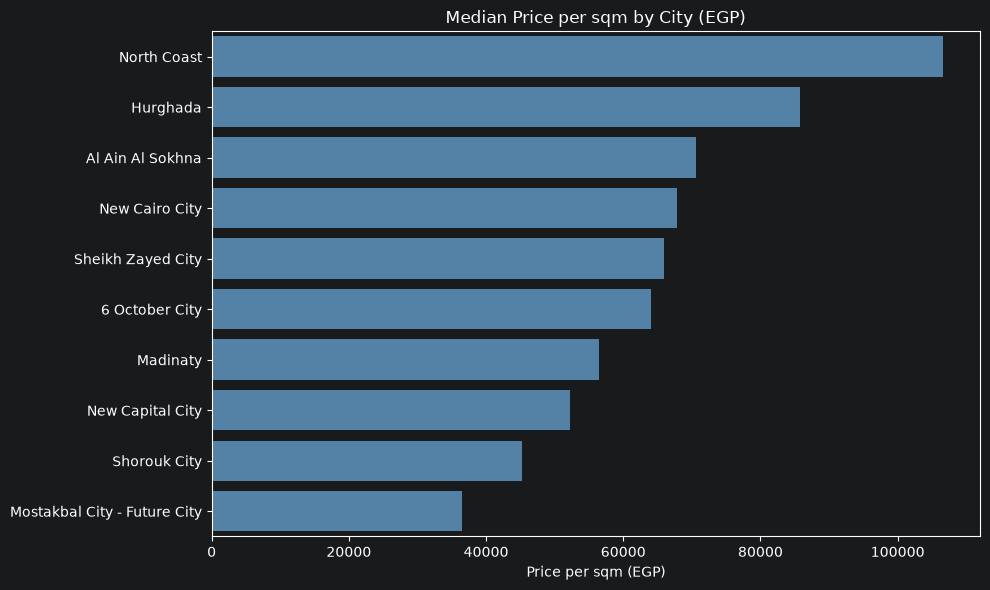

In [36]:
counts = df["city"].value_counts()
data = df[df["city"].isin(counts[counts >= 200].index)]

result = (data.groupby("city")["price_per_sqm"]
              .median()
              .sort_values(ascending=False))
print(result)

plt.figure(figsize=(10, 6))
sns.barplot(x=result.values, y=result.index, color="steelblue")
plt.title("Median Price per sqm by City (EGP)")
plt.xlabel("Price per sqm (EGP)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("price_per_sqm_by_city.png", dpi=150)
plt.show()

In [44]:
#df = df.drop(columns=["amenities"])
df = df.rename(columns={"area_name": "compound"})
df.shape
df.head(20)

,id,title,price,property_type,location,latitude,longitude,bedrooms,bathrooms,size,price_per_sqm,compound,city
19979,8572018,SEA VIEW chalet ( 3 bedrooms ) - RTM - Foukabay,11350000.0,Chalet,"Fouka Bay, Qesm Marsa Matrouh, North Coast",31.090607,27.940727,3.0,2.0,129.0,87984.496124,Fouka Bay,North Coast
19981,8572009,TWIN HOUSE ( SEA VIEW ) 360 m For sale at D-Bay,23000000.0,Twin House,"D-Bay, Qesm Ad Dabaah, North Coast",31.080320,28.393543,5.0,6.0,360.0,63888.888889,D-Bay,North Coast
19982,52721554,"Ready garden apart 158 sqm in Beverly, 5yrs plan",5600000.0,Apartment,"Six West, Beverly Hills, Sheikh Zayed Compound...",30.071228,30.936045,2.0,3.0,158.0,35443.037975,Six West,Sheikh Zayed City
19984,52719731,RTM 164 sqm garden apt in New Cairo installments,3500000.0,Apartment,"El Patio 7, 5th Settlement Compounds, The 5th ...",30.008648,31.428759,3.0,3.0,164.0,21341.463415,El Patio 7,New Cairo City
19985,52972565,Corner Apt Bahry prime location 155m with 3 Be...,4400000.0,Apartment,"Mountain View iCity, 5th Settlement Compounds,...",30.069424,31.599737,3.0,3.0,155.0,28387.096774,Mountain View iCity,New Cairo City
19987,51121662,Villa for sale in Rabwa with swimming pool ove...,68000000.0,Villa,"Al Rabwa, Sheikh Zayed Compounds, Sheikh Zaye...",30.065697,30.987492,7.0,7.0,1150.0,59130.434783,Al Rabwa,Sheikh Zayed City
19988,52711116,Largest Villa in La Vista City Modern Delivered,40000000.0,Villa,"La Vista City, New Capital Compounds, New Capi...",30.002905,31.595442,6.0,6.0,560.0,71428.571429,La Vista City,New Capital City
19989,51047484,Lowest Price 182m Prime Location Delivered in S1,6000000.0,Apartment,"S1, Sarai, Mostakbal City Compounds, Mostakbal...",30.090050,31.702806,3.0,4.0,182.0,32967.032967,S1,Mostakbal City - Future City
19990,8676848,chalet with installments at swan lake north,22000099.0,Chalet,"Swan Lake North Coast, Qesm Ad Dabaah, North C...",31.074837,28.061289,4.0,4.0,230.0,95652.604348,Swan Lake North Coast,North Coast
19991,8702676,S villa for sale at taj city ready to move,17000000.0,Villa,"Taj City, 5th Settlement Compounds, The 5th Se...",30.078453,31.426924,3.0,4.0,278.0,61151.079137,Taj City,New Cairo City


In [45]:
import pandas as pd
import plotly.express as px

df = pd.read_csv("cleaned_egypt_real_estate.csv")

fig = px.scatter_map(
    df,
    lat="latitude",
    lon="longitude",
    color="price_per_sqm",
    range_color=[20000, 150000],
    color_continuous_scale="Turbo",
    hover_name="city",
    hover_data=["property_type", "price", "size"],
    zoom=5.5,
    height=700,
    title="Price per sqm across Egypt (EGP)",
)
fig.update_traces(marker=dict(size=5, opacity=0.6))
fig.update_layout(map_style="open-street-map", margin=dict(l=0, r=0, t=40, b=0))

fig.write_html("price_map.html")
fig.show()